# 04 - Local scoring simulator

**Author of this notebook:** Qusai (qusai branch). Part of plan step 5
("identify the areas and ordering of work units").

## Why do we need this?
The course website scores a submission, but (a) it is only reachable from the SFU
network and (b) it only gives back one number. To *design* a good set of work units
we need to evaluate thousands of candidate plans quickly and see **where** the money
goes. So `src/pipeplan/simulator.py` re-implements the professor's evaluation rules
(Project_Description.md) so that we can score a plan on our own laptops.

## The rules we implemented
| Rule | Where in code |
|---|---|
| cost = 100 + (surface_rate x area)^0.85 + 200 x metres of **non-polyurethane** pipe | `simulator.work_unit_cost` |
| surface_rate = sum of the rates of the **distinct** surfaces among **all** pipes wholly inside (poly pipes included) | `world.RATE_BY_MASK`, `World.surface_rate` |
| a pipe is "wholly inside" iff **both end points** are inside the closed circle | `World.members` |
| $10M arrives at the start of each year 2027-2051; unspent money carries over | `simulate` |
| units run strictly in file order; a unit that doesn't fit waits for next year and **blocks** later units | `simulate` |
| a unit with no non-poly pipe left inside is skipped for free | `simulate` |
| pipes that leaked 2019-2026 are already polyurethane | `World.nonpoly0` |
| score = (25 x 10M - replacement spend) - cost of leaks that happen before the pipe is replaced | `simulate` |

## Three ways to score a plan
1. `simulate(...)` - exact rules for **one** concrete future (a leak time + cost for every pipe).
2. `monte_carlo(...)` - repeat (1) over many futures drawn from the group's leak-risk model.
3. `expected_score(...)` - a fast approximation (no randomness) used inside the optimiser.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "tests"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipeplan.world import load_world, SURFACE_RATE
from pipeplan.simulator import prepare, simulate, monte_carlo, expected_score, work_unit_cost, fixed_cost

pd.set_option("display.width", 160)

## 1. Load the network
`load_world()` reads `data/raw/pipes.csv`, `data/raw/train.csv` and the leak-risk table
`data/processed/leak_risk_cheryl.csv` (Cheryl's logistic + gamma model: for each pipe
the yearly leak probability `p_leak_annual` and the expected cost of a leak
`cost_if_leak` - copied from her `priority_all.csv`, branch `Cheryl`, commit f7472c3).

We check our numbers against what the group already found.

In [2]:
w = load_world()
checks = pd.Series({
    "pipes in network": w.n,
    "still non-polyurethane on 1 Jan 2027": int(w.nonpoly0.sum()),
    "  of which iron = MUST be covered": int(w.required.sum()),
    "  of which copper/brass = optional": int((w.nonpoly0 & ~w.required).sum()),
    "pipes with blank material (treated as iron)": int(w.material_missing.sum()),
    "metres of non-poly pipe": round(float(w.length[w.nonpoly0].sum())),
    "unavoidable linear cost, $ (200 x metres)": round(200 * float(w.length[w.nonpoly0].sum())),
})
checks

pipes in network                                  43039
still non-polyurethane on 1 Jan 2027              27248
  of which iron = MUST be covered                 26245
  of which copper/brass = optional                 1003
pipes with blank material (treated as iron)           8
metres of non-poly pipe                          471777
unavoidable linear cost, $ (200 x metres)      94355354
dtype: int64

These match Daniel's EDA (27,248 non-poly pipes, 471,777 m, ~$94.4M linear floor) and
Cheryl's `priority_iron.csv` (26,245 iron pipes = 26,237 known iron + 8 blank-material pipes).

## 2. Worked example: cost of one real work unit, by hand vs simulator
We take the first iron road pipe, put a circle around it, and compute the cost
step by step.

In [3]:
i = int(np.flatnonzero(w.required & (w.surf_bit == (1 << 3)))[0])  # code 3 = "road"
cx, cy = w.mx[i], w.my[i]
r = round(w.length[i] / 2 + 0.10, 2)
members = w.members(cx, cy, r)
print("pipe", w.pipe_id[i], "length %.2f m" % w.length[i], "| circle centre (%.2f, %.2f) radius %.2f" % (cx, cy, r))
print("pipes wholly inside the circle:", [str(w.pipe_id[m]) for m in members])

s = w.surface_rate(members)
area = np.pi * r**2
nonpoly_m = w.length[members][w.nonpoly0[members]].sum()
print(f"\nsurface rate  = {s}  (road = {SURFACE_RATE['road']} plus any other surface among the pipes inside)")
print(f"area          = pi x {r}^2 = {area:.2f} m^2")
print(f"area term     = ({s} x {area:.2f})^0.85 = {(s*area)**0.85:.2f}")
print(f"linear term   = 200 x {nonpoly_m:.2f} m = {200*nonpoly_m:.2f}")
print(f"TOTAL         = 100 + {(s*area)**0.85:.2f} + {200*nonpoly_m:.2f} = {100 + (s*area)**0.85 + 200*nonpoly_m:.2f}")

prep = prepare(w, np.array([[cx, cy, r]]))
print("\nsimulator says:", simulate(w, prep)["spend"], "| work_unit_cost() says:", work_unit_cost(s, r, nonpoly_m))

pipe P01071 length 40.73 m | circle centre (3685.85, 2188.71) radius 20.47
pipes wholly inside the circle: ['P09751', 'P43101', 'P09752', 'P42175', 'P43074', 'P42182', 'P43242', 'P09980', 'P43244', 'P01071', 'P42180', 'P09979', 'P43075', 'P42174', 'P42181']

surface rate  = 67.0  (road = 17.0 plus any other surface among the pipes inside)
area          = pi x 20.47^2 = 1316.39 m^2
area term     = (67.0 x 1316.39)^0.85 = 15982.37
linear term   = 200 x 208.29 m = 41658.46
TOTAL         = 100 + 15982.37 + 41658.46 = 57740.83

simulator says: 57740.83 | work_unit_cost() says: 57740.83


## 3. Unit tests
`tests/test_pipeplan.py` builds tiny hand-made networks (where every number can be
checked on paper) and tests: the cost formula, the "surface rate counts poly pipes too"
rule, the "wholly inside" rule, leaked pipes being free, budget carry-over, a big unit
blocking later small ones, leaks making later circles cheaper or skipped, and that the
sampled leak times follow the annual probabilities.

In [4]:
import test_pipeplan

tests = [v for k, v in sorted(vars(test_pipeplan).items()) if k.startswith("test_")]
for t in tests:
    t()
    print("ok  ", t.__name__)
print(f"\n{len(tests)} tests passed")

ok   test_a_unit_that_does_not_fit_blocks_later_cheaper_units
ok   test_budget_carry_over_and_blocking


ok   test_expected_score_matches_monte_carlo_when_budget_is_loose
ok   test_leak_after_replacement_is_not_counted
ok   test_leak_before_execution_costs_money_but_removes_linear_cost
ok   test_leaked_and_polyurethane_pipes_are_not_replaced_or_billed
ok   test_min_enclosing_circle
ok   test_missing_material_treated_as_required_iron
ok   test_pipe_must_be_wholly_inside


ok   test_sampled_leak_times_follow_the_annual_probability
ok   test_single_circle_cost_matches_formula
ok   test_surface_rate_counts_every_pipe_inside_even_polyurethane

12 tests passed


## 4. Seeing the budget mechanics
A toy plan: three identical circles with a deliberately small yearly budget, so that
carry-over and queue-blocking are visible.

In [5]:
from test_pipeplan import make_world, cost_by_hand

toy = make_world([(f"P{k}", "cast iron", "grassland", 1000 * k, 0, 1000 * k + 10, 0) for k in range(3)])
toy_prep = prepare(toy, np.array([[1000 * k + 5, 0, 5.02] for k in range(3)]))
res = simulate(toy, toy_prep, annual_budget=3000, n_years=5)
print("each circle costs about $%.2f; yearly budget $3000" % cost_by_hand(3, 5.02, 10))
print("year in which each circle is executed:", list(res["exec_year"]), "(budget carries over, so one circle every year)")

each circle costs about $2204.55; yearly budget $3000
year in which each circle is executed: [0, 1, 2] (budget carries over, so one circle every year)


## 5. A first real plan, to calibrate expectations
The most naive plan: one tiny circle per non-poly pipe (the circle through its two end
points), sorted by Cheryl-style *loss per metre*. We score it all three ways.
(Better plans are built in notebooks 05 and 06.)

In [6]:
idx = np.flatnonzero(w.nonpoly0)
order = idx[np.argsort(-(w.loss_rate[idx] / w.length[idx]))]
single = np.column_stack([w.mx[order], w.my[order], w.length[order] / 2 + 0.10])
sp = prepare(w, single)

ex = expected_score(w, sp)
mc = monte_carlo(w, sp, n_draws=40, seed=7)
ev = simulate(w, sp)  # no leaks at all = the "nothing ever leaks" extreme
pd.DataFrame({
    "expected_score (fast approx.)": [ex["spend"], ex["leak_cost"], ex["score"]],
    "monte_carlo mean (40 futures)": [mc["spend_mean"], mc["leak_cost_mean"], mc["score_mean"]],
}, index=["replacement spend $", "leak cost $", "score $"]).round(0)

,expected_score (fast approx.),monte_carlo mean (40 futures)
replacement spend $,162063196.0,131871324.0
leak cost $,36788385.0,32825886.0
score $,51148420.0,85302790.0


### Why does Monte Carlo score higher than the fast approximation?
In the real rules a pipe that leaks **before** its circle is dug becomes polyurethane
(project notes), so the circle no longer pays the $200/m for it, and a circle whose pipes
have all leaked is skipped entirely. Leaks therefore *reduce replacement spend* and make
the timeline finish earlier. `expected_score` ignores this (it keeps every pipe in the
ground until its circle runs), so it is a **conservative** score that is cheap to
compute; `monte_carlo` includes the effect. We use the fast one for optimisation and the
Monte Carlo for the final report - orderings that win under one also win under the other
(checked in notebook 06).

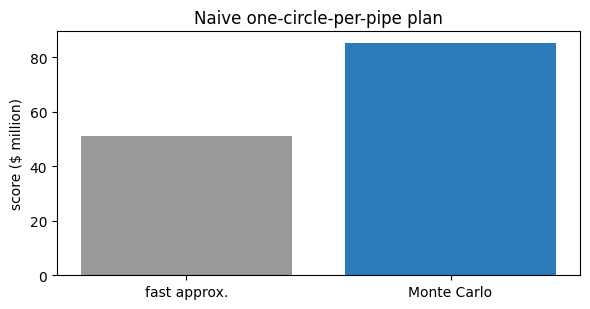

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(["fast approx.", "Monte Carlo"], [ex["score"] / 1e6, mc["score_mean"] / 1e6], color=["#999", "#2b7bba"])
ax.set_ylabel("score ($ million)")
ax.set_title("Naive one-circle-per-pipe plan")
plt.tight_layout()
plt.show()

## 6. Limitations (please read before quoting any score)
* The simulator is only as good as the **leak-risk model** behind it (Cheryl's logistic
  regression on material, surface, lay year and length, and her gamma cost model). It
  assumes a **constant yearly hazard** per pipe, so risk does not grow as the network ages.
* Leak sizes are heavy-tailed (road leaks average ~$235k, with a few multi-million
  outliers). Monte Carlo uses the *mean* cost for every leak, so the real score on the
  website will be noisier than the standard deviations we report.
* We could not check against the professor's evaluator, so details we inferred from the
  text (closed-circle boundary, order of events inside a year) could differ slightly.
  **Recommended calibration:** submit the plan from notebook 06 on the website and
  compare the accepted/rejected verdict and the score with our prediction.